# 04 - Evaluasi Final di TEST
Tujuan: mengukur model hasil notebook 03 pada **TEST (300 query)** dengan galeri = seluruh TRAIN (1050 gambar), lalu menganalisis hasilnya.

Aturan main:
- Konfigurasi sudah dikunci di notebook 03 (`artifacts/final_config.json`). **Jangan mengubah konfigurasi setelah melihat angka TEST.**
- Notebook ini hanya memuat model dan menghitung metrik, tidak ada training. Aman dijalankan ulang.
- Prasyarat: `final.pt`, `final_gallery.npy`, `final_gallery_manifest.csv`, `final_config.json` di folder `artifacts/`.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

DATA_DIR = Path("../data/raw")
MANIFEST = Path("../data/manifest.csv")
ART = Path("../artifacts")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE, BATCH, SEED = 224, 32, 42
np.random.seed(SEED)
print("device:", DEVICE)

device: cuda


## 2. Data dan konfigurasi final

In [2]:
EXT = {".jpg", ".jpeg", ".png"}

def build_manifest(data_dir):
    rows = []
    for split_dir in ["TRAIN", "TEST"]:
        for p in sorted((data_dir / split_dir).rglob("*")):
            if p.suffix.lower() in EXT:
                rows.append({"path": p.relative_to(data_dir).as_posix(),
                             "class": p.parent.name, "split": split_dir.lower()})
    return pd.DataFrame(rows)

df = pd.read_csv(MANIFEST) if MANIFEST.exists() else build_manifest(DATA_DIR)
classes = sorted(set(df["class"].tolist()))
cls2idx = {c: i for i, c in enumerate(classes)}

# galeri: urutan harus sama dengan final_gallery.npy
gallery_df = pd.read_csv(ART / "embeddings" / "final_gallery_manifest.csv")
test_df = df[df["split"] == "test"].reset_index(drop=True)
gl = gallery_df["class"].to_numpy()
ql = test_df["class"].to_numpy()
g_emb = np.load(ART / "embeddings" / "final_gallery.npy")
cfg = json.load(open(ART / "final_config.json"))

assert len(gallery_df) == len(g_emb), "manifest galeri dan embedding tidak sama panjang"
print(len(classes), "kelas |", len(gallery_df), "galeri |", len(test_df), "test")
print("konfigurasi final:", {k: cfg[k] for k in ["tag", "backbone", "n_unfreeze", "optimizer", "lr", "lr_head", "epochs"]})

15 kelas | 1050 galeri | 300 test
konfigurasi final: {'tag': 'D6_eff_u4_sgd_hi', 'backbone': 'efficientnet_b0', 'n_unfreeze': 4, 'optimizer': 'sgd', 'lr': 0.01, 'lr_head': 0.01, 'epochs': 30}


## 3. Model, transformasi, dan metrik (sama dengan notebook 02 dan 03)

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class ImgDS(Dataset):
    def __init__(self, frame):
        self.paths = frame["path"].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return eval_tfm(Image.open(DATA_DIR / self.paths[i]).convert("RGB"))

class Net(nn.Module):
    def __init__(self, name, n_classes):
        super().__init__()
        if name == "resnet50":
            b = models.resnet50(weights=None); dim = b.fc.in_features; b.fc = nn.Identity()
        elif name == "mobilenet_v2":
            b = models.mobilenet_v2(weights=None); dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        elif name == "efficientnet_b0":
            b = models.efficientnet_b0(weights=None); dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        else:
            raise ValueError(name)
        self.name, self.backbone = name, b
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, n_classes))
    def embed(self, x):
        return self.backbone(x)

@torch.no_grad()
def embed_frame(net, frame):
    net.eval()
    loader = DataLoader(ImgDS(frame), batch_size=BATCH, num_workers=0)
    f = np.concatenate([net.embed(x.to(DEVICE)).cpu().numpy() for x in loader])
    return f / np.linalg.norm(f, axis=1, keepdims=True)

def p_at_k_per_query(sims, q_labels, g_labels, k):
    idx = np.argsort(-sims, axis=1)[:, :k]
    return (g_labels[idx] == q_labels[:, None]).mean(axis=1)

def ap_per_query(sims, q_labels, g_labels):
    out = []
    for s, y in zip(sims, q_labels):
        rel = (g_labels[np.argsort(-s)] == y)
        if rel.sum() == 0:
            out.append(np.nan); continue
        prec = np.cumsum(rel) / (np.arange(len(rel)) + 1)
        out.append((prec * rel).sum() / rel.sum())
    return np.array(out)

net = Net(cfg["backbone"], len(classes)).to(DEVICE)
net.load_state_dict(torch.load(ART / "models" / "final.pt", map_location=DEVICE))
net.eval()
print("model dimuat:", cfg["backbone"])

model dimuat: efficientnet_b0


C:\Users\yuhanidz\AppData\Local\Temp\ipykernel_27792\4223897874.py:54: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(ART / "models" / "final.p

## 4. Embedding TEST dan pemeriksaan konsistensi
Galeri dihitung ulang dari model yang dimuat dan dibandingkan dengan `final_gallery.npy`. Kalau tidak cocok, ada yang salah (model, urutan, atau transformasi) dan angka di bawah tidak boleh dipakai.

In [4]:
# cek konsistensi pada 64 gambar galeri pertama
chk = embed_frame(net, gallery_df.iloc[:64])
max_diff = float(np.abs(chk - g_emb[:64]).max())
print("selisih maksimum embedding galeri:", max_diff)
assert max_diff < 1e-3, "embedding galeri tidak cocok dengan model yang dimuat"

q_emb = embed_frame(net, test_df)
sims = q_emb @ g_emb.T
print("embedding TEST:", q_emb.shape, "| sims:", sims.shape)

selisih maksimum embedding galeri: 0.0
embedding TEST: (300, 1280) | sims: (300, 1050)


## 5. Hasil utama di TEST

In [5]:
p5_q  = p_at_k_per_query(sims, ql, gl, 5)
p10_q = p_at_k_per_query(sims, ql, gl, 10)
ap_q  = ap_per_query(sims, ql, gl)

test_res = {"P@5": p5_q.mean(), "P@10": p10_q.mean(), "mAP": np.nanmean(ap_q)}

# interval kepercayaan 95% dengan bootstrap atas query
rng = np.random.default_rng(SEED)
def boot_ci(v, n=2000):
    v = v[~np.isnan(v)]
    means = [rng.choice(v, len(v), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

rows = []
for name, v in [("P@5", p5_q), ("P@10", p10_q), ("mAP", ap_q)]:
    lo, hi = boot_ci(v)
    rows.append({"metrik": name, "nilai": round(float(np.nanmean(v)), 4),
                 "CI95_bawah": round(float(lo), 4), "CI95_atas": round(float(hi), 4)})
test_table = pd.DataFrame(rows)
test_table.to_csv(ART / "results_test.csv", index=False)
test_table

,metrik,nilai,CI95_bawah,CI95_atas
0,P@5,0.798,0.7553,0.8380
1,P@10,0.785,0.7440,0.8223
2,mAP,0.720,0.6855,0.7557


## 6. Perbandingan: baseline, validation, dan TEST

In [6]:
comp = []

base_csv = ART / "results_baseline.csv"
if base_csv.exists():
    b = pd.read_csv(base_csv)
    b = b[b.iloc[:, 0].astype(str).str.contains("Efficient", case=False)]
    if len(b):
        r = b.iloc[0]
        comp.append({"tahap": "Baseline pretrained (validation)", "P@5": r.get("P@5"), "P@10": r.get("P@10"), "mAP": r.get("mAP")})

ft = pd.read_csv(ART / "results_finetune.csv")
base_tag = cfg["tag"]
sub = ft[ft["tag"].str.replace(r"_seed\d+$", "", regex=True) == base_tag]
comp.append({"tahap": f"Fine-tuning {base_tag} (validation, rata-rata {len(sub)} seed)",
             "P@5": sub["val_P@5"].mean(), "P@10": sub["val_P@10"].mean(), "mAP": sub["val_mAP"].mean()})
comp.append({"tahap": "Final di TEST (latih di seluruh TRAIN)",
             "P@5": test_res["P@5"], "P@10": test_res["P@10"], "mAP": test_res["mAP"]})

pd.DataFrame(comp).round(4)

,tahap,P@5,P@10,mAP
0,Baseline pretrained (validation),0.5410,0.4695,0.2715
1,"Fine-tuning D6_eff_u4_sgd_hi (validation, rata...",0.8098,0.7975,0.7303
2,Final di TEST (latih di seluruh TRAIN),0.7980,0.7850,0.7200


Catatan membaca tabel: baris validation memakai galeri 840 gambar, baris TEST memakai galeri 1050 gambar (lebih banyak relevan per kelas), jadi angkanya tidak persis setara. Perbedaan kecil antara validation dan TEST wajar; selisih besar (TEST jauh lebih rendah) patut dicurigai sebagai overfitting ke validation atau perbedaan distribusi.

## 7. Metrik per kelas

In [7]:
per = pd.DataFrame({"kelas": ql, "P@5": p5_q, "P@10": p10_q, "AP": ap_q})
top1_pred = gl[sims.argmax(axis=1)]
per["top1_benar"] = (top1_pred == ql).astype(float)

per_class = (per.groupby("kelas")[["P@5", "P@10", "AP", "top1_benar"]].mean()
                .assign(n_query=per.groupby("kelas").size())
                .sort_values("AP", ascending=False).round(4))
per_class.to_csv(ART / "results_test_per_class.csv")
print("Top-1 benar (keseluruhan):", round(float(per["top1_benar"].mean()), 4))
per_class

Top-1 benar (keseluruhan): 0.8133


,P@5,P@10,AP,top1_benar,n_query
kelas,,,,,
Batik Megamendung,1.00,1.000,0.9757,1.00,20
Batik Poleng,1.00,1.000,0.9753,1.00,20
Batik Insang,0.98,0.985,0.9441,1.00,20
Batik Dayak,0.91,0.895,0.8535,0.95,20
Batik Tambal,0.91,0.880,0.8280,0.90,20
Batik Parang,0.92,0.900,0.8233,0.90,20
Batik Ikat Celup,0.75,0.755,0.7349,0.70,20
Batik Cendrawasih,0.70,0.705,0.7029,0.70,20
Batik Kawung,0.74,0.735,0.6808,0.75,20


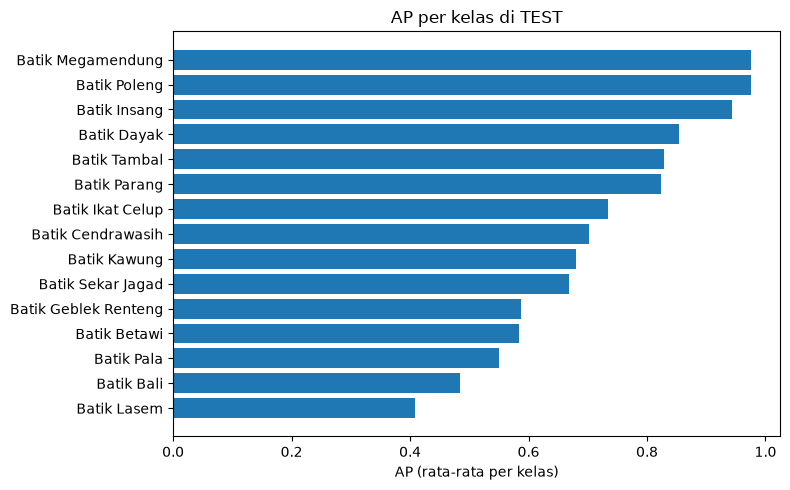

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
pc = per_class.sort_values("AP")
ax.barh(pc.index, pc["AP"])
ax.set_xlabel("AP (rata-rata per kelas)"); ax.set_title("AP per kelas di TEST")
plt.tight_layout(); plt.show()

## 8. Confusion matrix Top-1 dan pasangan yang sering tertukar

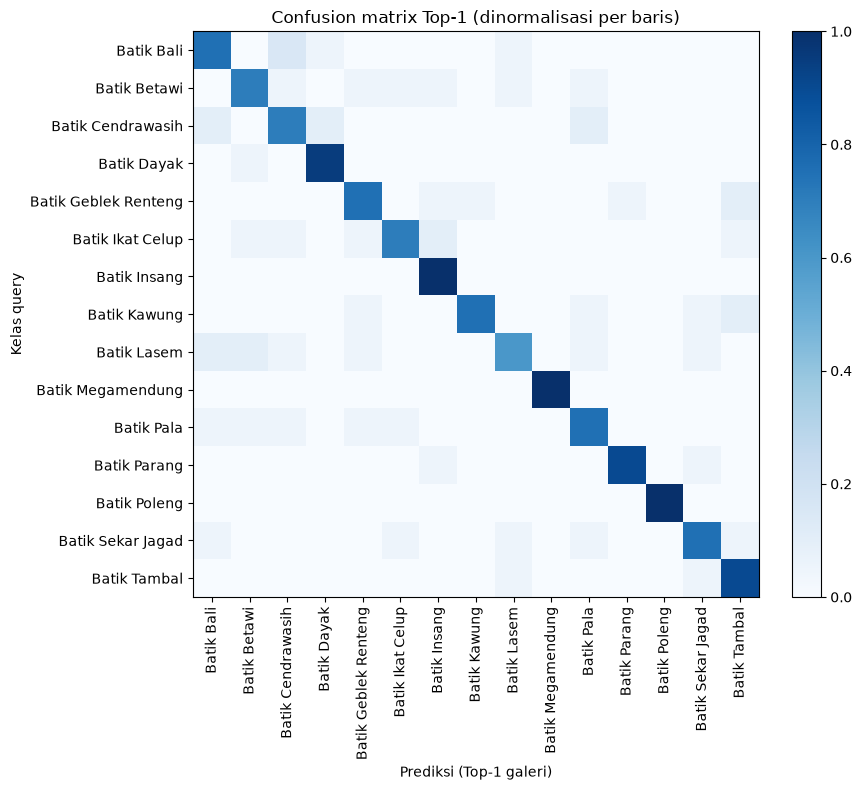

Batik Bali -> Batik Cendrawasih         3
Batik Cendrawasih -> Batik Pala         2
Batik Cendrawasih -> Batik Dayak        2
Batik Cendrawasih -> Batik Bali         2
Batik Geblek Renteng -> Batik Tambal    2
Batik Ikat Celup -> Batik Insang        2
Batik Kawung -> Batik Tambal            2
Batik Lasem -> Batik Bali               2
Batik Lasem -> Batik Betawi             2
Batik Bali -> Batik Lasem               1
Name: count, dtype: int64

In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(ql, top1_pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90); ax.set_yticklabels(classes)
ax.set_xlabel("Prediksi (Top-1 galeri)"); ax.set_ylabel("Kelas query")
ax.set_title("Confusion matrix Top-1 (dinormalisasi per baris)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

pd.Series([f"{a} -> {b}" for a, b in zip(ql, top1_pred) if a != b]).value_counts().head(10)

## 9. Contoh query: berhasil dan gagal

P@5 sempurna: 209 query | Top-1 salah: 56 query
== Contoh berhasil ==


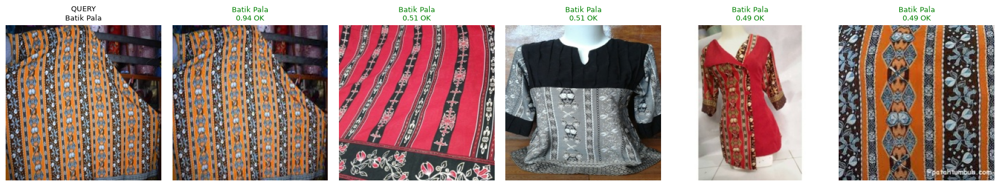

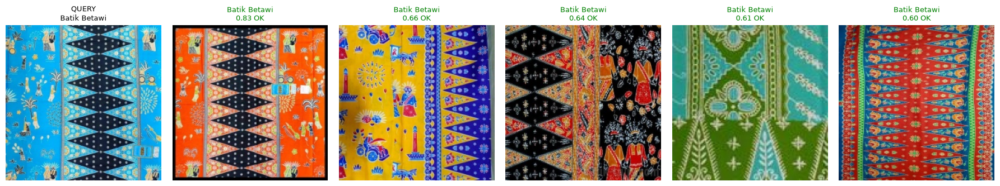

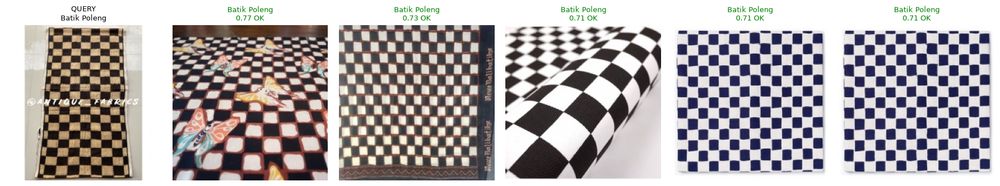

In [10]:
def show_query(i, k=5):
    s = sims[i]
    idx = np.argsort(-s)[:k]
    fig, ax = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3.2))
    ax[0].imshow(Image.open(DATA_DIR / test_df["path"][i]).convert("RGB"))
    ax[0].set_title("QUERY\n" + ql[i], fontsize=9)
    for j, gi in enumerate(idx, 1):
        ax[j].imshow(Image.open(DATA_DIR / gallery_df["path"][gi]).convert("RGB"))
        ok = gl[gi] == ql[i]
        ax[j].set_title(f"{gl[gi]}\n{s[gi]:.2f} {'OK' if ok else 'X'}", fontsize=9,
                        color="green" if ok else "red")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

rng2 = np.random.default_rng(SEED)
good = np.where(p5_q == 1.0)[0]
bad = np.where(top1_pred != ql)[0]
print(f"P@5 sempurna: {len(good)} query | Top-1 salah: {len(bad)} query")

print("== Contoh berhasil ==")
for i in rng2.choice(good, size=min(3, len(good)), replace=False):
    show_query(i)

== Contoh gagal (Top-1 salah) ==


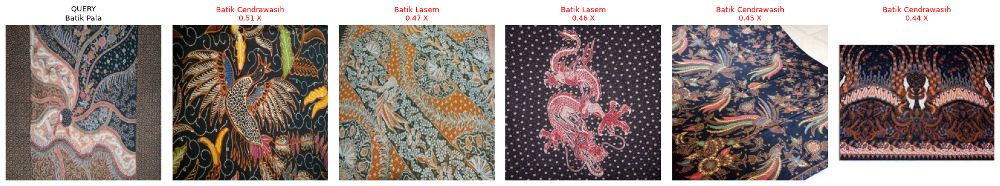

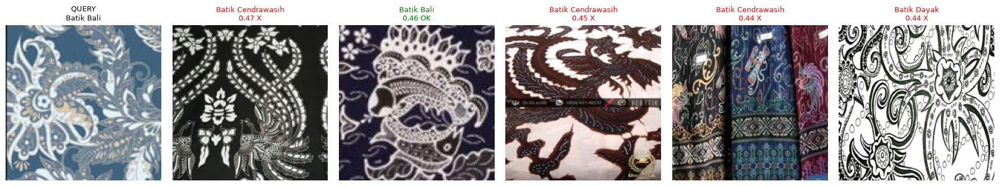

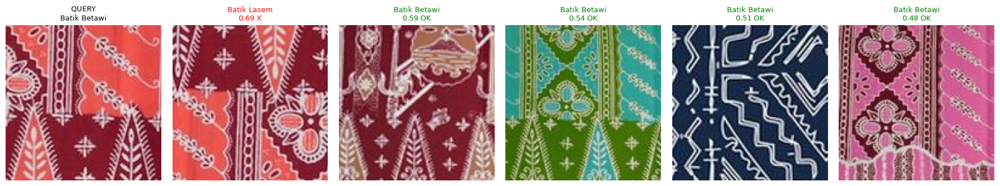

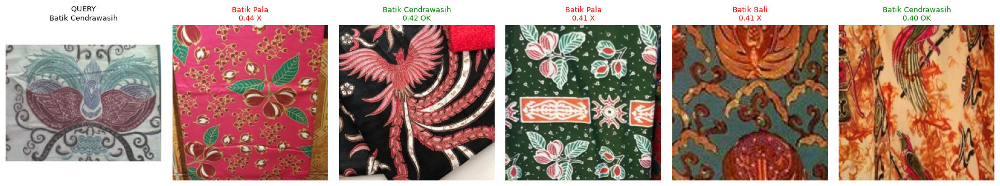

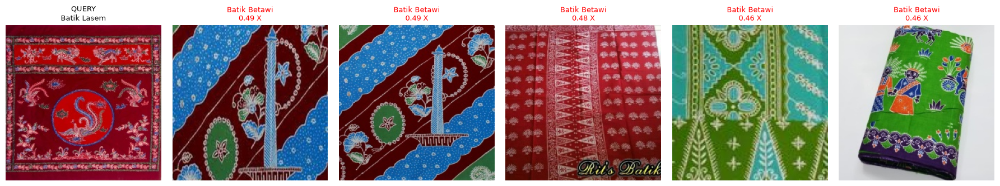

In [11]:
print("== Contoh gagal (Top-1 salah) ==")
for i in rng2.choice(bad, size=min(5, len(bad)), replace=False):
    show_query(i)

## 10. Pemeriksaan kebocoran TRAIN/TEST
Mencari pasangan TEST dan galeri dengan kemiripan kosinus sangat tinggi (kemungkinan gambar duplikat). Kalau banyak, angka TEST bisa terlalu optimis dan perlu dilaporkan atau dibersihkan.

query dengan kemiripan >= 0.99: 10 dari 300
query dengan kemiripan >= 0.98: 10 dari 300
query dengan kemiripan >= 0.95: 12 dari 300

Contoh pasangan paling mirip:


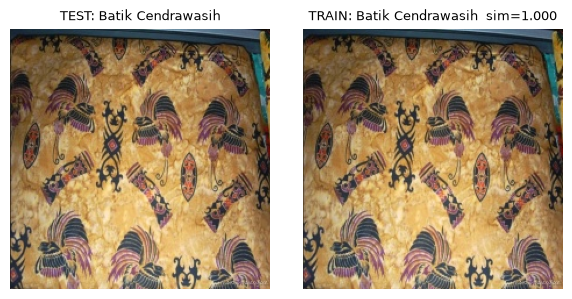

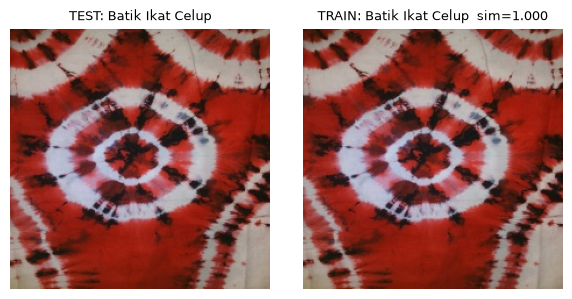

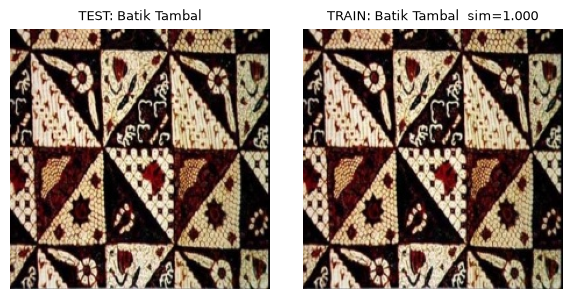

In [12]:
max_sim = sims.max(axis=1)
nn_idx = sims.argmax(axis=1)
for thr in [0.99, 0.98, 0.95]:
    print(f"query dengan kemiripan >= {thr}: {(max_sim >= thr).sum()} dari {len(max_sim)}")

dup = np.where(max_sim >= 0.98)[0]
print("\nContoh pasangan paling mirip:")
for i in np.argsort(-max_sim)[:3]:
    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(Image.open(DATA_DIR / test_df["path"][i]).convert("RGB")); ax[0].set_title(f"TEST: {ql[i]}", fontsize=9)
    ax[1].imshow(Image.open(DATA_DIR / gallery_df["path"][nn_idx[i]]).convert("RGB")); ax[1].set_title(f"TRAIN: {gl[nn_idx[i]]}  sim={max_sim[i]:.3f}", fontsize=9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

## 11. Ringkasan untuk laporan
Isi angka dari sel di atas:
- Hasil utama TEST (bagian 5, lengkap dengan CI 95%).
- Peningkatan dari baseline ke fine-tuning (bagian 6).
- Kelas terkuat dan terlemah (bagian 7) dan pasangan kelas yang sering tertukar (bagian 8).
- Hasil pemeriksaan duplikat/kebocoran (bagian 10).

File yang dihasilkan: `artifacts/results_test.csv`, `artifacts/results_test_per_class.csv`.

### 1. Konfigurasi & Skenario Pengujian

* **Arsitektur & Parameter Model**: `efficientnet_b0` (`D6_eff_u4_sgd_hi`) dengan *n_unfreeze* = 4, *optimizer* SGD, *learning rate* 0.01 (*backbone* & *head*), dan dilatih selama 30 *epoch* menggunakan seluruh data **TRAIN** (1.050 gambar sebagai galeri referensi).
* **Data Evaluasi**: 300 gambar *query* dari set **TEST** (terdiri dari 15 kelas motif batik, masing-masing 20 gambar *query*).
* **Validasi Konsistensi**: Selisih maksimum antara *embedding* galeri yang dihitung ulang dengan artefak `final_gallery.npy` adalah **0.0**, memastikan bobot model dan pipeline transformasi sudah konsisten.


### 2. Performa Utama pada Data TEST

Model menunjukkan peningkatan performa yang sangat signifikan dibandingkan *baseline* *pretrained* dan memiliki generalisasi yang stabil terhadap hasil *validation*:

| Tahap Evaluasi | P@5 | P@10 | mAP | Keterangan / CI 95% (TEST) |
| --- | --- | --- | --- | --- |
| **Baseline Pretrained (Val)** | 0.5410 | 0.4695 | 0.2715 | Galeri 840 gambar |
| **Fine-Tuning (Val, rata-rata seed)** | 0.8098 | 0.7975 | 0.7303 | Galeri 840 gambar |
| **Final di TEST (Seluruh TRAIN)** | **0.7980** | **0.7850** | **0.7200** | **Top-1 Akurasi: 81.33%** |

* **Interval Kepercayaan 95% (Bootstrap 2.000x pada TEST)**:
* **P@5**: `0.7553 – 0.8380`
* **P@10**: `0.7440 – 0.8223`
* **mAP**: `0.6855 – 0.7557`


* **Analisis *Overfitting***: Selisih metrik antara *validation* (`mAP = 0.7303`) dan *test* (`mAP = 0.7200`) sangat kecil (~0.01), menandakan model tidak mengalami *overfitting* terhadap data validasi dan mampu menggeneralisasi pola visual batik dengan baik.

### 3. Analisis Performa per Kelas

Dari total 300 *query*, **209 *query*** mendapatkan hasil **P@5 sempurna (1.0)**, sementara **56 *query*** mengalami kesalahan pada prediksi Top-1:

* **Kelas dengan Performa Terbaik (AP > 0.90)**:
* **Batik Megamendung**: `AP = 0.9757` (`P@5 = 1.00`, `Top-1 = 100%`)
* **Batik Poleng**: `AP = 0.9753` (`P@5 = 1.00`, `Top-1 = 100%`)
* **Batik Insang**: `AP = 0.9441` (`P@5 = 0.98`, `Top-1 = 100%`)
* *Karakteristik*: Motif-motif ini memiliki struktur geometris atau bentuk ikonik yang sangat khas (seperti pola awan pada Megamendung dan kotak-kotak kontras tinggi pada Poleng) sehingga mudah dipisahkan oleh *embedding* model.


* **Kelas dengan Performa Terendah (AP < 0.60)**:
* **Batik Lasem**: `AP = 0.4076` (`P@5 = 0.56`, `Top-1 = 60%`)
* **Batik Bali**: `AP = 0.4848` (`P@5 = 0.62`, `Top-1 = 75%`)
* **Batik Pala**: `AP = 0.5504` (`P@5 = 0.77`, `Top-1 = 75%`)
* **Batik Betawi**: `AP = 0.5836` (`P@5 = 0.68`, `Top-1 = 70%`)
* **Batik Geblek Renteng**: `AP = 0.5877` (`P@5 = 0.72`, `Top-1 = 75%`)


### 4. Pola Kesalahan (*Confusion Matrix* Top-1)

Pasangan kelas yang paling sering tertukar pada peringkat teratas (Top-1) meliputi:

1. **Batik Bali $\leftrightarrow$ Batik Cendrawasih** (5 kasus tertukar dua arah: 3 Bali $\rightarrow$ Cendrawasih, 2 Cendrawasih $\rightarrow$ Bali) — kemungkinan disebabkan oleh kemiripan ornamen flora/fauna yang padat dan warna cerah.
2. **Batik Lasem $\rightarrow$ Batik Bali** (2 kasus) dan **Batik Lasem $\rightarrow$ Batik Betawi** (2 kasus) — dipengaruhi oleh variasi warna merah/cerah dan kepadatan isen-isen pada motif pesisiran/kontemporer.
3. **Batik Cendrawasih $\rightarrow$ Batik Pala / Batik Dayak** (masing-masing 2 kasus) — memiliki kemiripan pola sulur dan bentuk melengkung.
